# 04 · Stability of tactic associations across years

**Question.** Do the observed-to-expected associations among tactics recur from year to year as tactic use changes? We compare every year from 2008 to 2024 with the other 16 years pooled, then examine whether the result depends on pair selection, year weights or the interval between observations.

For pair $h$ in year $t$, the association is $\theta_{ht}=\log_2((O_{ht}+0.5)/(E_{ht}+0.5))$. The comparison profile pools observed and expected counts over the other years before taking their ratio: $\theta_{h,-t}=\log_2((\sum_{s\ne t}O_{hs}+0.5)/(\sum_{s\ne t}E_{hs}+0.5))$. Each comparison uses eligible pairs with expected counts of at least 5 and nonzero reference variance on both sides. We report Pearson and Spearman correlations, sign agreement, and sign agreement for strong contrasts, defined by $|\theta_{h,-t}|\ge\log_2 1.5$.

The notebook also compares adjacent years, all pairs of years and the pooled periods 2008–2018 and 2021–2024. Sensitivity analyses use pairs evaluable in every year, equal weight for each year's total pair count, and eligibility based on 2008–2018 alone.

Three diagnostics describe sampling effects: day-clustered split halves estimate reliability; a day-block bootstrap describes variability in correlations and log ratios; and calendar-month permutations compare the observed temporal arrangement with reassigned months. Cochran's $Q$ and $I^2$ summarize heterogeneity in the bootstrap log ratios. Their interpretation is discussed beside each analysis. The within-year-calibrated departure statistic is computed in notebook 05.

Inputs are the aggregate and day-level counts produced by notebook 02. Resampling keeps all actions on a protest day together and holds their reference expectations fixed. Settings and random seeds are recorded in `config/analysis.json`. Tables and diagnostic figures are displayed before export.

In [1]:
import os

for k in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(k, "2")
import json, itertools, time
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

ROOT = Path(os.environ.get("PROTEST_ROOT", Path.cwd())).expanduser().resolve()
if not (ROOT / "config" / "analysis.json").is_file():
    ROOT = ROOT.parent
if not (ROOT / "config" / "analysis.json").is_file():
    raise FileNotFoundError(
        "Open this notebook from the repository root or its notebooks folder, or set PROTEST_ROOT."
    )
CFG = json.loads((ROOT / "config" / "analysis.json").read_text())
TAB = ROOT / "results" / "tables"
AGG = ROOT / "results" / "aggregates"
LOCAL = ROOT / "data_local"
DIAG = ROOT / "results" / "diagnostics"
DIAG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)


def display_figure(fig, name):
    """Show and export the same diagnostic figure."""
    display(fig)
    fig.savefig(DIAG / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)


def display_and_save_table(df, name, index=False, float_format="%.4f"):
    """Display and export the same table in CSV and LaTeX formats."""
    display(df)
    df.to_csv(TAB / f"{name}.csv", index=index)
    df.to_latex(
        TAB / f"{name}.tex", index=index, escape=True, float_format=lambda x: float_format % x
    )
    return df


PAIRS = np.array(list(itertools.combinations(range(1, 36), 2)))
YEARS = np.arange(2008, 2025)
T = len(YEARS)
SPECS = ["N1", "N2", "N2_clean", "N2_allmedia", "N2_order", "N1_k2"]
CALIBRATED = ["N2", "N1", "N2_clean"]
elig = np.load(AGG / "eligible_primary.npy")
STRONG = np.log2(1.5)
dic = pd.read_csv(TAB / "tactic_dictionary.csv").set_index("code")
print("eligible pairs:", int(elig.sum()))


eligible pairs: 291


In [2]:
def lr(O, E):
    """Log2 observed-to-expected ratio with a 0.5 pseudo-count on both counts."""
    return np.log2((O + 0.5) / (E + 0.5))


def compare(a, b, mask, strong_ref):
    """Agreement between two effect vectors on mask; strong contrasts defined on strong_ref."""
    x, y = a[mask], b[mask]
    s = np.abs(strong_ref[mask]) >= STRONG
    out = {"pairs": int(mask.sum())}
    if mask.sum() >= 3 and x.std() > 0 and y.std() > 0:
        out.update(pearson=pearsonr(x, y)[0], spearman=spearmanr(x, y)[0])
    else:
        out.update(pearson=np.nan, spearman=np.nan)
    out.update(
        sign_agreement=float((np.sign(x) == np.sign(y)).mean()) if mask.any() else np.nan,
        strong_pairs=int(s.sum()),
        strong_sign_agreement=float((np.sign(x[s]) == np.sign(y[s])).mean()) if s.any() else np.nan,
        strong_excess=int((strong_ref[mask] >= STRONG).sum()),
        strong_deficit=int((strong_ref[mask] <= -STRONG).sum()),
    )
    return out


data = {}
for name in SPECS:
    z = np.load(AGG / f"null_{name}.npz")
    C = z["counts"].astype(np.float64)  # 999 x 17 x 595
    data[name] = dict(
        Oy=z["observed_year"].astype(float),
        Ey=C.mean(0),
        sdy=C.std(0, ddof=1),
        tot=C.sum(1),
        counts=C,
    )


## 1. Each year against all other years

In [3]:
yvr = []
theta_store = {}
for name, d in data.items():
    Ot, Et, sdt = d["Oy"], d["Ey"], d["sdy"]
    Oall, Eall = Ot.sum(0), Et.sum(0)
    th_year = np.zeros((T, 595))
    th_rest = np.zeros((T, 595))
    masks = np.zeros((T, 595), bool)
    for ti, yr in enumerate(YEARS):
        Or, Er = Oall - Ot[ti], Eall - Et[ti]
        sdr = (d["tot"] - d["counts"][:, ti, :]).std(0, ddof=1)
        m = elig & (Et[ti] >= 5) & (Er >= 5) & (sdt[ti] > 0) & (sdr > 0)
        a, b = lr(Ot[ti], Et[ti]), lr(Or, Er)
        th_year[ti], th_rest[ti], masks[ti] = a, b, m
        yvr.append(
            {
                "reference": name,
                "year": yr,
                **compare(a, b, m, b),
                "actions_multi_pairs_observed": int(Ot[ti].sum()),
            }
        )
    theta_store[name] = (th_year, th_rest, masks)
yvr = display_and_save_table(pd.DataFrame(yvr), "annual_year_vs_rest")
yvr[yvr.reference.isin(["N2", "N1"])].pivot(
    index="year", columns="reference", values=["pairs", "pearson", "strong_sign_agreement"]
).round(3)


,reference,year,pairs,pearson,spearman,sign_agreement,strong_pairs,strong_sign_agreement,strong_excess,strong_deficit,actions_multi_pairs_observed
0,N1,2008,59,0.750428,0.863530,0.966102,47,0.978723,14,33,1601
1,N1,2009,54,0.854826,0.882142,0.944444,43,0.976744,13,30,1114
2,N1,2010,39,0.903508,0.889069,0.923077,31,0.967742,10,21,889
3,N1,2011,82,0.889183,0.903310,0.853659,60,0.950000,20,40,2283
4,N1,2012,62,0.892019,0.938103,0.983871,48,1.000000,16,32,1257
...,...,...,...,...,...,...,...,...,...,...,...
97,N1_k2,2020,27,0.849413,0.765568,0.740741,16,0.812500,6,10,649
98,N1_k2,2021,22,0.874618,0.941276,0.909091,15,1.000000,3,12,677
99,N1_k2,2022,19,0.848068,0.859649,0.842105,13,1.000000,1,12,608
100,N1_k2,2023,10,0.688083,0.818182,1.000000,7,1.000000,1,6,429


pairs        pearson        strong_sign_agreement       
reference     N1     N2      N1     N2                    N1     N2
year                                                               
2008        59.0   61.0   0.750  0.798                 0.979  1.000
2009        54.0   51.0   0.855  0.833                 0.977  0.964
2010        39.0   32.0   0.904  0.882                 0.968  1.000
2011        82.0   84.0   0.889  0.921                 0.950  1.000
2012        62.0   62.0   0.892  0.859                 1.000  0.946
2013        62.0   66.0   0.886  0.894                 0.936  0.974
2014        56.0   60.0   0.860  0.876                 0.975  0.935
2015        32.0   32.0   0.828  0.773                 0.913  1.000
2016        59.0   66.0   0.795  0.700                 0.897  0.941
2017        43.0   41.0   0.881  0.875                 1.000  0.958
2018        53.0   63.0   0.892  0.860                 0.974  0.970
2019       120.0  119.0   0.792  0.799                 0.942  0.942
2020       104.0   95.0   0.794  0.697                 0.944  0.875
2021        85.0   84.0   0.845  0.803                 0.898  0.974
2022        72.0   77.0   0.835  0.730                 0.979  0.944
2023        39.0   36.0   0.831  0.868                 0.962  0.944
2024        28.0   28.0   0.827  0.784                 0.895  1.000

## 2. Adjacent years, all pairs of years and the lag profile

,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,NaN,0.776680,0.815336,0.855331,0.771422,0.687062,0.702797,0.743218,0.605213,0.733977,0.706194,0.757207,0.663157,0.634759,0.644968,0.761376,0.723067
2009,0.776680,NaN,0.732095,0.820308,0.833739,0.864216,0.872872,0.690982,0.816571,0.813833,0.770235,0.773178,0.709328,0.832658,0.671072,0.836918,0.721666
2010,0.815336,0.732095,NaN,0.894180,0.886940,0.775709,0.645349,0.737903,0.651768,0.757071,0.778123,0.762415,0.746433,0.856086,0.703322,0.720421,0.584442
2011,0.855331,0.820308,0.894180,NaN,0.855699,0.808469,0.793970,0.719976,0.672511,0.832521,0.841254,0.881554,0.766691,0.753760,0.762093,0.706648,0.665728
2012,0.771422,0.833739,0.886940,0.855699,NaN,0.862651,0.823125,0.762231,0.759784,0.806458,0.809411,0.841580,0.790810,0.869416,0.770941,0.866686,0.731072
2013,0.687062,0.864216,0.775709,0.808469,0.862651,NaN,0.882598,0.829323,0.873233,0.861874,0.844103,0.741104,0.803418,0.835172,0.747856,0.838592,0.820651
2014,0.702797,0.872872,0.645349,0.793970,0.823125,0.882598,NaN,0.780949,0.821109,0.876279,0.818350,0.720435,0.710346,0.841227,0.754405,0.878684,0.748349
2015,0.743218,0.690982,0.737903,0.719976,0.762231,0.829323,0.780949,NaN,0.806030,0.860943,0.825315,0.667560,0.756427,0.819372,0.741814,0.877048,0.817924
2016,0.605213,0.816571,0.651768,0.672511,0.759784,0.873233,0.821109,0.806030,NaN,0.766378,0.739283,0.562377,0.637823,0.799466,0.654624,0.800933,0.764814
2017,0.733977,0.813833,0.757071,0.832521,0.806458,0.861874,0.876279,0.860943,0.766378,NaN,0.888920,0.753472,0.809127,0.832309,0.795179,0.821655,0.743913


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,0,42,36,55,47,47,46,27,38,35,44,50,42,36,37,29,25
2009,42,0,36,43,40,43,40,24,34,32,42,45,37,38,35,30,24
2010,36,36,0,37,30,32,31,22,27,29,35,34,27,25,25,24,22
2011,55,43,37,0,58,54,53,31,52,41,51,65,57,47,47,36,27
2012,47,40,30,58,0,55,51,32,47,37,46,58,50,41,43,33,24
2013,47,43,32,54,55,0,53,32,48,40,49,62,47,43,43,35,25
2014,46,40,31,53,51,53,0,32,48,41,47,55,45,40,41,33,25
2015,27,24,22,31,32,32,32,0,32,29,32,32,31,27,27,24,18
2016,38,34,27,52,47,48,48,32,0,39,42,54,46,38,40,28,22
2017,35,32,29,41,37,40,41,29,39,0,39,43,35,33,33,29,22


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,NaN,0.839557,0.864427,0.807571,0.778389,0.688671,0.721270,0.666282,0.691569,0.612749,0.668512,0.740391,0.648790,0.667890,0.698467,0.617552,0.792129
2009,0.839557,NaN,0.790042,0.804430,0.781518,0.799627,0.798129,0.643966,0.710190,0.813018,0.693295,0.743639,0.708483,0.755112,0.698661,0.839768,0.754341
2010,0.864427,0.790042,NaN,0.870502,0.887261,0.785890,0.720156,0.875644,0.767155,0.750638,0.767641,0.659734,0.674411,0.823689,0.531973,0.774043,0.767071
2011,0.807571,0.804430,0.870502,NaN,0.804351,0.833145,0.793278,0.664568,0.715901,0.780327,0.833666,0.856340,0.675764,0.688630,0.733562,0.668559,0.714126
2012,0.778389,0.781518,0.887261,0.804351,NaN,0.768773,0.809491,0.624185,0.734961,0.777552,0.761670,0.786067,0.757652,0.808419,0.670150,0.863217,0.659111
2013,0.688671,0.799627,0.785890,0.833145,0.768773,NaN,0.863464,0.666599,0.833681,0.873035,0.808433,0.711781,0.841554,0.789778,0.762408,0.843856,0.684350
2014,0.721270,0.798129,0.720156,0.793278,0.809491,0.863464,NaN,0.613166,0.702271,0.947887,0.849623,0.769533,0.784768,0.727191,0.764549,0.812763,0.608894
2015,0.666282,0.643966,0.875644,0.664568,0.624185,0.666599,0.613166,NaN,0.741281,0.667283,0.755986,0.555870,0.735425,0.680796,0.741287,0.804766,0.872525
2016,0.691569,0.710190,0.767155,0.715901,0.734961,0.833681,0.702271,0.741281,NaN,0.728581,0.612126,0.483832,0.496689,0.676258,0.595422,0.831211,0.659960
2017,0.612749,0.813018,0.750638,0.780327,0.777552,0.873035,0.947887,0.667283,0.728581,NaN,0.830990,0.697929,0.735376,0.710676,0.733818,0.835850,0.709396


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,0,46,31,59,52,52,48,30,40,35,52,53,44,43,43,29,26
2009,46,0,31,46,42,44,43,27,35,31,46,44,39,40,37,27,26
2010,31,31,0,31,28,29,27,20,24,27,31,29,24,26,26,22,20
2011,59,46,31,0,57,59,55,31,53,38,56,70,55,52,48,31,28
2012,52,42,28,57,0,56,51,30,42,36,49,58,49,47,45,31,25
2013,52,44,29,59,56,0,53,32,49,37,52,63,49,51,48,30,26
2014,48,43,27,55,51,53,0,30,49,39,50,53,47,46,45,32,27
2015,30,27,20,31,30,32,30,0,28,24,31,31,29,27,24,21,18
2016,40,35,24,53,42,49,49,28,0,34,45,55,46,43,40,25,22
2017,35,31,27,38,36,37,39,24,34,0,37,38,33,33,32,27,23


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,NaN,0.849863,0.882027,0.787745,0.799389,0.702957,0.861886,0.695446,0.797522,0.741053,0.666851,0.772824,0.613956,0.694747,0.818334,0.884799,0.980212
2009,0.849863,NaN,0.806480,0.673210,0.648599,0.653902,0.777029,0.771732,0.782042,0.870822,0.824317,0.726831,0.746115,0.776521,0.720381,0.957222,0.948881
2010,0.882027,0.806480,NaN,0.797200,0.898219,0.898100,0.836056,0.783129,0.895764,0.923150,0.768707,0.777989,0.727147,0.901302,0.863561,0.933926,0.947115
2011,0.787745,0.673210,0.797200,NaN,0.805598,0.821156,0.851049,0.733640,0.801126,0.910373,0.842727,0.868162,0.757294,0.742905,0.876275,0.884627,0.931458
2012,0.799389,0.648599,0.898219,0.805598,NaN,0.734092,0.839956,0.534551,0.808540,0.818857,0.766900,0.831053,0.783554,0.824288,0.731177,0.879106,0.923861
2013,0.702957,0.653902,0.898100,0.821156,0.734092,NaN,0.861790,0.700056,0.930817,0.930780,0.788958,0.784248,0.793320,0.837428,0.889227,0.909657,0.960069
2014,0.861886,0.777029,0.836056,0.851049,0.839956,0.861790,NaN,0.675473,0.761193,0.939077,0.866249,0.868738,0.901127,0.745524,0.847227,0.864083,0.948962
2015,0.695446,0.771732,0.783129,0.733640,0.534551,0.700056,0.675473,NaN,0.803139,0.721491,0.805080,0.543254,0.679878,0.651653,0.807026,0.681983,0.972901
2016,0.797522,0.782042,0.895764,0.801126,0.808540,0.930817,0.761193,0.803139,NaN,0.840710,0.777512,0.757687,0.664203,0.781864,0.872456,0.644864,0.844201
2017,0.741053,0.870822,0.923150,0.910373,0.818857,0.930780,0.939077,0.721491,0.840710,NaN,0.888535,0.844196,0.935824,0.769651,0.867320,0.950593,0.965158


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,0,22,12,31,29,28,24,15,20,18,24,27,20,19,18,10,9
2009,22,0,12,23,23,23,23,13,18,16,22,24,19,20,15,11,9
2010,12,12,0,12,12,12,12,7,10,11,12,11,8,9,8,7,6
2011,31,23,12,0,34,32,29,15,25,20,27,38,28,26,22,12,9
2012,29,23,12,34,0,33,28,14,24,20,26,36,28,26,25,14,9
2013,28,23,12,32,33,0,30,16,26,20,27,35,25,25,25,13,9
2014,24,23,12,29,28,30,0,15,25,21,25,29,24,24,23,14,9
2015,15,13,7,15,14,16,15,0,14,10,16,15,13,13,10,7,7
2016,20,18,10,25,24,26,25,14,0,17,22,26,23,19,19,11,7
2017,18,16,11,20,20,20,21,10,17,0,17,19,15,16,15,10,8


... (4 outputs left out)

,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,NaN,0.879956,0.878358,0.964741,0.908423,0.807399,0.765184,0.890165,0.664520,0.857793,0.735097,0.858127,0.867437,0.929567,0.839990,0.710153,0.707475
2009,0.879956,NaN,0.869407,0.877116,0.924402,0.860410,0.826908,0.777233,0.718900,0.742542,0.717549,0.941535,0.896812,0.870583,0.634945,0.802163,0.705082
2010,0.878358,0.869407,NaN,0.845588,0.771702,0.824275,0.809419,0.780640,0.827085,0.932166,0.937727,0.835746,0.733572,0.942621,0.789456,0.836632,0.879128
2011,0.964741,0.877116,0.845588,NaN,0.856747,0.800043,0.823192,0.885275,0.751498,0.846030,0.770346,0.893817,0.938513,0.859971,0.719407,0.824555,0.770889
2012,0.908423,0.924402,0.771702,0.856747,NaN,0.877576,0.887088,0.637987,0.728622,0.803563,0.771593,0.794241,0.793187,0.812461,0.783358,0.775484,0.838960
2013,0.807399,0.860410,0.824275,0.800043,0.877576,NaN,0.913258,0.834274,0.750247,0.844545,0.920152,0.695013,0.763724,0.791382,0.586959,0.898303,0.892432
2014,0.765184,0.826908,0.809419,0.823192,0.887088,0.913258,NaN,0.753252,0.749561,0.859397,0.920251,0.864520,0.891941,0.855096,0.730710,0.938476,0.903402
2015,0.890165,0.777233,0.780640,0.885275,0.637987,0.834274,0.753252,NaN,0.862605,0.955745,0.840195,0.737977,0.779482,0.929149,0.872246,0.655583,0.817513
2016,0.664520,0.718900,0.827085,0.751498,0.728622,0.750247,0.749561,0.862605,NaN,0.839590,0.818840,0.729885,0.865066,0.800795,0.666672,0.645675,0.732086
2017,0.857793,0.742542,0.932166,0.846030,0.803563,0.844545,0.859397,0.955745,0.839590,NaN,0.859298,0.864237,0.432693,0.610607,0.802254,0.870887,0.825481


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
2008,0,15,11,17,16,18,14,10,17,13,12,14,13,10,10,7,8
2009,15,0,10,15,12,14,14,10,15,12,12,11,10,9,9,7,8
2010,11,10,0,10,11,11,11,9,10,10,10,11,9,10,9,8,7
2011,17,15,10,0,17,19,19,10,19,13,14,18,13,12,10,7,8
2012,16,12,11,17,0,19,16,10,15,12,12,16,13,12,9,7,7
2013,18,14,11,19,19,0,17,10,17,13,13,16,13,12,10,7,8
2014,14,14,11,19,16,17,0,11,16,13,15,16,13,13,12,8,10
2015,10,10,9,10,10,10,11,0,13,12,12,12,11,11,10,8,7
2016,17,15,10,19,15,17,16,13,0,14,15,18,15,14,14,9,9
2017,13,12,10,13,12,13,13,12,14,0,14,12,11,12,10,7,8


,reference,year,next_year,pairs,pearson,spearman,sign_agreement,strong_pairs,strong_sign_agreement,strong_excess,strong_deficit
0,N1,2008,2009,42,0.776680,0.814278,0.904762,29,0.965517,12,17
1,N1,2009,2010,36,0.732095,0.712227,0.861111,28,0.892857,10,18
2,N1,2010,2011,37,0.894180,0.889521,0.837838,26,0.884615,8,18
3,N1,2011,2012,58,0.855699,0.896152,0.879310,42,0.976190,13,29
4,N1,2012,2013,55,0.862651,0.888817,0.890909,42,0.928571,11,31
...,...,...,...,...,...,...,...,...,...,...,...
91,N1_k2,2019,2020,19,0.859152,0.715789,0.631579,13,0.846154,7,6
92,N1_k2,2020,2021,17,0.801214,0.872549,0.823529,11,1.000000,4,7
93,N1_k2,2021,2022,16,0.960321,0.929412,0.937500,11,0.909091,0,11
94,N1_k2,2022,2023,9,0.553683,0.783333,1.000000,5,1.000000,1,4


,reference,lag_years,n_year_pairs,mean_pearson,median_pearson,min_pearson,max_pearson
0,N1,1,16,0.811159,0.813875,0.716472,0.894180
1,N1,2,15,0.796698,0.820308,0.579148,0.886940
2,N1,3,14,0.800034,0.818506,0.562377,0.876279
3,N1,4,13,0.751169,0.759784,0.637823,0.864216
4,N1,5,12,0.754278,0.768350,0.578651,0.872872
...,...,...,...,...,...,...,...
91,N1_k2,12,5,0.838198,0.838960,0.789456,0.870583
92,N1_k2,13,4,0.793008,0.803761,0.634945,0.929567
93,N1_k2,14,3,0.840427,0.839990,0.802163,0.879128
94,N1_k2,15,2,0.707617,0.707617,0.705082,0.710153


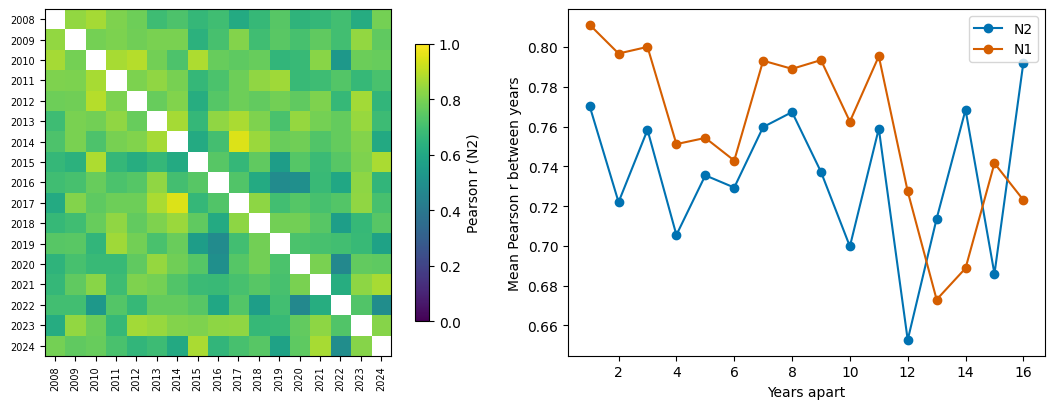

lag_years,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
reference,,,,,,,,,,,,,,,,
N1,0.811,0.797,0.800,0.751,0.754,0.743,0.793,0.789,0.793,0.762,0.795,0.727,0.673,0.689,0.742,0.723
N2,0.770,0.722,0.758,0.705,0.735,0.729,0.760,0.767,0.737,0.700,0.759,0.653,0.714,0.768,0.686,0.792


In [4]:
adj = []
mat = {}
lag_rows = []
for name, d in data.items():
    Ot, Et, sdt = d["Oy"], d["Ey"], d["sdy"]
    th = lr(Ot, Et)
    M = np.full((T, T), np.nan)
    Np = np.zeros((T, T), int)
    for i in range(T):
        for j in range(T):
            if i == j:
                continue
            m = elig & (Et[i] >= 5) & (Et[j] >= 5) & (sdt[i] > 0) & (sdt[j] > 0)
            if m.sum() >= 3:
                M[i, j] = pearsonr(th[i][m], th[j][m])[0]
                Np[i, j] = m.sum()
            if j == i + 1:
                adj.append(
                    {
                        "reference": name,
                        "year": YEARS[i],
                        "next_year": YEARS[j],
                        **compare(th[i], th[j], m, th[i]),
                    }
                )
    mat[name] = M
    for metric, values in (("pearson", M), ("support", Np)):
        year_matrix = pd.DataFrame(values, index=YEARS, columns=YEARS)
        display(year_matrix)
        year_matrix.to_csv(TAB / f"year_by_year_{metric}_{name}.csv")
    for lag in range(1, T):
        vals = np.array([M[i, i + lag] for i in range(T - lag)])
        lag_rows.append(
            {
                "reference": name,
                "lag_years": lag,
                "n_year_pairs": len(vals),
                "mean_pearson": np.nanmean(vals),
                "median_pearson": np.nanmedian(vals),
                "min_pearson": np.nanmin(vals),
                "max_pearson": np.nanmax(vals),
            }
        )
adj = display_and_save_table(pd.DataFrame(adj), "annual_adjacent_years")
lagp = display_and_save_table(pd.DataFrame(lag_rows), "annual_lag_profile")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
im = ax[0].imshow(mat["N2"], vmin=0, vmax=1, cmap="viridis")
ax[0].set_xticks(range(T), YEARS, rotation=90, fontsize=7)
ax[0].set_yticks(range(T), YEARS, fontsize=7)
fig.colorbar(im, ax=ax[0], shrink=0.8, label="Pearson r (N2)")
for name, c in [("N2", "#0072B2"), ("N1", "#D55E00")]:
    z = lagp[lagp.reference == name]
    ax[1].plot(z.lag_years, z.mean_pearson, "o-", color=c, label=name)
ax[1].set_xlabel("Years apart")
ax[1].set_ylabel("Mean Pearson r between years")
ax[1].legend()
fig.tight_layout()
display_figure(fig, "annual_stability_and_lag")
lagp[lagp.reference.isin(["N2", "N1"])].pivot(
    index="lag_years", columns="reference", values="mean_pearson"
).round(3).T


## 3. Sensitivity to pair support and year weights

The common-support comparison uses only pairs evaluable in every year. Equal year weights scale each year's observed and expected counts to the mean total number of pair occurrences. The early-period selection uses tactic frequencies and expected pair counts from 2008–2018, allowing us to check whether selection on the full record affects the annual comparisons.

In [5]:
rows = []
for name, d in data.items():
    th_year, th_rest, masks = theta_store[name]
    common = masks.all(0)
    for ti, yr in enumerate(YEARS):
        rows.append(
            {
                "reference": name,
                "variant": "common_support",
                "year": yr,
                **compare(th_year[ti], th_rest[ti], common, th_rest[ti]),
            }
        )
    # equal weight: each other year contributes as if it had the mean number of observed pairs
    Ot, Et = d["Oy"], d["Ey"]
    w = Ot.sum(1).mean() / Ot.sum(1)
    for ti, yr in enumerate(YEARS):
        ww = w.copy()
        ww[ti] = 0
        b = lr((ww[:, None] * Ot).sum(0), (ww[:, None] * Et).sum(0))
        rows.append(
            {
                "reference": name,
                "variant": "equal_year_weight",
                "year": yr,
                **compare(th_year[ti], b, masks[ti], b),
            }
        )
# Early-period selection: both tactics >= 50 actions in 2008-2018 and E_N1(2008-2018) >= 5
marg = pd.read_csv(TAB / "tactic_counts_by_year.csv").set_index("year")
marg.columns = marg.columns.astype(int)
m0818 = marg.loc[2008:2018].sum()
E_N1_0818 = data["N1"]["Ey"][:11].sum(0)
elig_early = (
    (m0818.loc[PAIRS[:, 0]].to_numpy() >= 50)
    & (m0818.loc[PAIRS[:, 1]].to_numpy() >= 50)
    & (E_N1_0818 >= 5)
)
np.save(AGG / "eligible_early_period.npy", elig_early)
for name, d in data.items():
    th_year, th_rest, masks = theta_store[name]
    Ot, Et, sdt = d["Oy"], d["Ey"], d["sdy"]
    for ti, yr in enumerate(YEARS):
        Er = Et.sum(0) - Et[ti]
        sdr = (d["tot"] - d["counts"][:, ti, :]).std(0, ddof=1)
        m = elig_early & (Et[ti] >= 5) & (Er >= 5) & (sdt[ti] > 0) & (sdr > 0)
        rows.append(
            {
                "reference": name,
                "variant": "early_period_selection",
                "year": yr,
                **compare(th_year[ti], th_rest[ti], m, th_rest[ti]),
            }
        )
sens = display_and_save_table(pd.DataFrame(rows), "annual_sensitivity_variants")
print(
    "early-period eligible pairs:",
    int(elig_early.sum()),
    "| common-support pairs (N2):",
    int(theta_store["N2"][2].all(0).sum()),
)
sens[sens.reference == "N2"].pivot(index="year", columns="variant", values="pearson").round(3)


,reference,variant,year,pairs,pearson,spearman,sign_agreement,strong_pairs,strong_sign_agreement,strong_excess,strong_deficit
0,N1,common_support,2008,13,0.871553,0.868132,0.923077,9,1.000000,3,6
1,N1,common_support,2009,13,0.850772,0.719780,0.846154,9,0.888889,3,6
2,N1,common_support,2010,13,0.792056,0.862637,0.923077,9,1.000000,3,6
3,N1,common_support,2011,13,0.957911,0.895604,0.846154,9,1.000000,3,6
4,N1,common_support,2012,13,0.850296,0.824176,0.923077,9,1.000000,3,6
...,...,...,...,...,...,...,...,...,...,...,...
301,N1_k2,early_period_selection,2020,26,0.859773,0.803761,0.769231,15,0.866667,6,9
302,N1_k2,early_period_selection,2021,22,0.874618,0.941276,0.909091,15,1.000000,3,12
303,N1_k2,early_period_selection,2022,18,0.865011,0.861713,0.833333,12,1.000000,1,11
304,N1_k2,early_period_selection,2023,10,0.688083,0.818182,1.000000,7,1.000000,1,6


early-period eligible pairs: 190 | common-support pairs (N2): 11


variant,common_support,early_period_selection,equal_year_weight
year,,,
2008,0.877,0.798,0.791
2009,0.871,0.833,0.837
2010,0.952,0.882,0.887
2011,0.963,0.921,0.910
2012,0.807,0.859,0.858
2013,0.864,0.894,0.903
2014,0.853,0.876,0.878
2015,0.914,0.773,0.787
2016,0.919,0.712,0.742


## 4. Associations in the earlier and later periods

Pooling 2008–2018 and 2021–2024 provides a comparison between the earlier and later parts of the record. Pair eligibility is determined from 2008–2018, and each pair must have an expected count of at least 5 and varying reference counts in both periods. The annual analyses above include all 17 years; this pooled comparison summarizes the two blocks used to compare changes in tactic use and pairing in notebook 06.

In [6]:
rows = []
for name, d in data.items():
    a_idx = YEARS <= 2018
    b_idx = YEARS >= 2021
    Oa, Ea = d["Oy"][a_idx].sum(0), d["Ey"][a_idx].sum(0)
    Ob, Eb = d["Oy"][b_idx].sum(0), d["Ey"][b_idx].sum(0)
    sda = d["counts"][:, a_idx, :].sum(1).std(0, ddof=1)
    sdb = d["counts"][:, b_idx, :].sum(1).std(0, ddof=1)
    m = elig_early & (Ea >= 5) & (Eb >= 5) & (sda > 0) & (sdb > 0)
    ta, tb = lr(Oa, Ea), lr(Ob, Eb)
    rows.append({"reference": name, **compare(ta, tb, m, ta)})
period_rep = display_and_save_table(pd.DataFrame(rows), "period_comparison")
period_rep.round(3)


,reference,pairs,pearson,spearman,sign_agreement,strong_pairs,strong_sign_agreement,strong_excess,strong_deficit
0,N1,113,0.857756,0.891144,0.876106,84,0.976190,33,51
1,N2,108,0.829156,0.842846,0.824074,64,0.953125,19,45
2,N2_clean,65,0.800798,0.845017,0.907692,46,0.956522,15,31
3,N2_allmedia,117,0.838686,0.864647,0.846154,76,0.947368,23,53
4,N2_order,104,0.813426,0.816227,0.836538,61,0.967213,18,43
5,N1_k2,41,0.855027,0.851916,0.902439,30,0.966667,8,22


,reference,pairs,pearson,spearman,sign_agreement,strong_pairs,strong_sign_agreement,strong_excess,strong_deficit
0,N1,113,0.858,0.891,0.876,84,0.976,33,51
1,N2,108,0.829,0.843,0.824,64,0.953,19,45
2,N2_clean,65,0.801,0.845,0.908,46,0.957,15,31
3,N2_allmedia,117,0.839,0.865,0.846,76,0.947,23,53
4,N2_order,104,0.813,0.816,0.837,61,0.967,18,43
5,N1_k2,41,0.855,0.852,0.902,30,0.967,8,22


## 5. Reliability and bootstrap calibration

For N2, N1 and N2 clean, 50 random splits of protest days estimate the reproducibility of the annual and pooled comparison profiles. The Spearman–Brown transformation gives their reliability estimates, whose geometric mean is the correlation ceiling. Dividing the observed correlation by this ceiling gives the disattenuated ratio.

The day-block bootstrap resamples days within each year 999 times. Each replicate supplies annual log ratios, annual-versus-rest correlations and disattenuated ratios. These are calibration diagnostics conditional on the reference expectations; the annual departure inference uses the statistic in notebook 05.

In [7]:
def load_days(name):
    """Load observed and expected pair counts by protest day and year index."""
    z = np.load(LOCAL / f"day_OE_{name}.npz", allow_pickle=True)
    days = pd.to_datetime(z["days"])
    yidx = days.year.to_numpy() - 2008
    return z["observed"].astype(np.float64), z["expected"].astype(np.float64), yidx


SPLITS = CFG["calibration"]["split_half"]["splits_per_year"]
B = CFG["calibration"]["correlation_bootstrap"]["B"]
K_BOOT_SPLITS = 5
rng_split = np.random.default_rng(CFG["calibration"]["split_half"]["seed"])
rng_boot = np.random.default_rng(CFG["calibration"]["correlation_bootstrap"]["seed"])


def corr(x, y):
    """Return Pearson correlation when both vectors vary and contain three pairs."""
    return np.corrcoef(x, y)[0, 1] if len(x) >= 3 and x.std() > 0 and y.std() > 0 else np.nan


def split_half_r(Od, Ed, mask, rng, n_splits):
    """Mean correlation between two random halves of the days (days kept whole)."""
    rs = []
    nd = len(Od)
    for _ in range(n_splits):
        perm = rng.permutation(nd)
        h1 = perm[: nd // 2]
        h2 = perm[nd // 2 :]
        a = lr(Od[h1].sum(0), Ed[h1].sum(0))
        b = lr(Od[h2].sum(0), Ed[h2].sum(0))
        rs.append(corr(a[mask], b[mask]))
    return float(np.nanmean(rs))


sb = lambda r: 2 * r / (1 + r)
calib_rows = []
boot_store = {}
for name in CALIBRATED:
    t0 = time.time()
    Od, Ed, yidx = load_days(name)
    th_year, th_rest, masks = theta_store[name]
    day_sets = [np.where(yidx == ti)[0] for ti in range(T)]
    rel_year = np.zeros(T)
    rel_rest = np.zeros(T)
    for ti in range(T):
        m = masks[ti]
        ry = split_half_r(Od[day_sets[ti]], Ed[day_sets[ti]], m, rng_split, SPLITS)
        rest_days = np.where(yidx != ti)[0]
        rr = split_half_r(Od[rest_days], Ed[rest_days], m, rng_split, SPLITS)
        rel_year[ti], rel_rest[ti] = sb(ry), sb(rr)
    # day-block bootstrap: resample days within every year; rest = all other resampled years
    r_boot = np.full((B, T), np.nan)
    dis_boot = np.full((B, T), np.nan)
    th_boot = np.zeros((B, T, 595), np.float32)
    Oyd = [Od[s] for s in day_sets]
    Eyd = [Ed[s] for s in day_sets]
    for b in range(B):
        Ob = np.zeros((T, 595))
        Eb = np.zeros((T, 595))
        rel_b = np.zeros(T)
        for ti in range(T):
            nd = len(day_sets[ti])
            w = np.bincount(rng_boot.integers(0, nd, nd), minlength=nd).astype(float)
            Ob[ti] = w @ Oyd[ti]
            Eb[ti] = w @ Eyd[ti]
            halves = rng_boot.random((K_BOOT_SPLITS, nd)) < 0.5
            W1 = halves * w
            W2 = (~halves) * w
            O1, E1, O2, E2 = W1 @ Oyd[ti], W1 @ Eyd[ti], W2 @ Oyd[ti], W2 @ Eyd[ti]
            m = masks[ti]
            rh = np.nanmean(
                [corr(lr(O1[k], E1[k])[m], lr(O2[k], E2[k])[m]) for k in range(K_BOOT_SPLITS)]
            )
            rel_b[ti] = sb(rh)
        th_boot[b] = lr(Ob, Eb)
        Oall, Eall = Ob.sum(0), Eb.sum(0)
        for ti in range(T):
            m = masks[ti]
            r = corr(lr(Ob[ti], Eb[ti])[m], lr(Oall - Ob[ti], Eall - Eb[ti])[m])
            r_boot[b, ti] = r
            dis_boot[b, ti] = r / np.sqrt(rel_b[ti] * rel_rest[ti]) if rel_b[ti] > 0 else np.nan
    boot_store[name] = th_boot
    obs = yvr[yvr.reference == name].set_index("year")
    for ti, yr in enumerate(YEARS):
        ceiling = np.sqrt(rel_year[ti] * rel_rest[ti]) if rel_year[ti] > 0 else np.nan
        calib_rows.append(
            {
                "reference": name,
                "year": yr,
                "pairs": int(masks[ti].sum()),
                "pearson": obs.loc[yr, "pearson"],
                "pearson_boot_lo": np.nanquantile(r_boot[:, ti], 0.025),
                "pearson_boot_hi": np.nanquantile(r_boot[:, ti], 0.975),
                "reliability_year": rel_year[ti],
                "reliability_rest": rel_rest[ti],
                "ceiling": ceiling,
                "disattenuated": obs.loc[yr, "pearson"] / ceiling,
                "disattenuated_boot_lo": np.nanquantile(dis_boot[:, ti], 0.025),
                "disattenuated_boot_hi": np.nanquantile(dis_boot[:, ti], 0.975),
            }
        )
    np.save(LOCAL / f"bootstrap_theta_{name}.npy", th_boot)
    print(name, "calibration seconds", round(time.time() - t0, 1), flush=True)
calib = pd.DataFrame(calib_rows)
display_and_save_table(calib, "annual_calibration")
calib[calib.reference == "N2"].round(3)


N2 calibration seconds 21.2


N1 calibration seconds 22.2


N2_clean calibration seconds 22.8


,reference,year,pairs,pearson,pearson_boot_lo,pearson_boot_hi,reliability_year,reliability_rest,ceiling,disattenuated,disattenuated_boot_lo,disattenuated_boot_hi
0,N2,2008,61,0.797851,0.635674,0.814481,0.758707,0.973545,0.859439,0.928340,0.778206,1.027722
1,N2,2009,51,0.832855,0.623516,0.846006,0.737562,0.968374,0.845125,0.985481,0.775595,1.117212
2,N2,2010,32,0.882188,0.716930,0.909924,0.840026,0.977830,0.906313,0.973381,0.829125,1.090862
3,N2,2011,84,0.920825,0.782031,0.892699,0.865231,0.956290,0.909622,1.012316,0.904615,1.058575
4,N2,2012,62,0.858609,0.726851,0.852653,0.846129,0.970939,0.906388,0.947286,0.834440,1.017478
5,N2,2013,66,0.894371,0.685276,0.859708,0.766015,0.956918,0.856162,1.044629,0.869148,1.155735
6,N2,2014,60,0.875953,0.691210,0.855117,0.740675,0.974120,0.849415,1.031242,0.867105,1.200193
7,N2,2015,32,0.772702,0.569118,0.830746,0.776371,0.982435,0.873346,0.884760,0.696793,1.080245
8,N2,2016,66,0.699757,0.501437,0.718955,0.691360,0.958557,0.814069,0.859580,0.648711,1.018304
9,N2,2017,41,0.875352,0.549282,0.845828,0.563301,0.975984,0.741467,1.180569,0.712484,1.772716


,reference,year,pairs,pearson,pearson_boot_lo,pearson_boot_hi,reliability_year,reliability_rest,ceiling,disattenuated,disattenuated_boot_lo,disattenuated_boot_hi
0,N2,2008,61,0.798,0.636,0.814,0.759,0.974,0.859,0.928,0.778,1.028
1,N2,2009,51,0.833,0.624,0.846,0.738,0.968,0.845,0.985,0.776,1.117
2,N2,2010,32,0.882,0.717,0.910,0.840,0.978,0.906,0.973,0.829,1.091
3,N2,2011,84,0.921,0.782,0.893,0.865,0.956,0.910,1.012,0.905,1.059
4,N2,2012,62,0.859,0.727,0.853,0.846,0.971,0.906,0.947,0.834,1.017
5,N2,2013,66,0.894,0.685,0.860,0.766,0.957,0.856,1.045,0.869,1.156
6,N2,2014,60,0.876,0.691,0.855,0.741,0.974,0.849,1.031,0.867,1.200
7,N2,2015,32,0.773,0.569,0.831,0.776,0.982,0.873,0.885,0.697,1.080
8,N2,2016,66,0.700,0.501,0.719,0.691,0.959,0.814,0.860,0.649,1.018
9,N2,2017,41,0.875,0.549,0.846,0.563,0.976,0.741,1.181,0.712,1.773


In most years the observed correlation lies near or above the upper end of its day-bootstrap percentile interval. Resampling adds count noise to the annual profiles and attenuates their correlation, shifting the percentile intervals downward. We interpret these intervals as a calibration diagnostic. The observed correlations, split-half ceilings and disattenuated point estimates describe the similarity of the profiles; the within-year-calibrated quasi-Poisson statistic in notebook 05 measures annual departures.

## 6. Heterogeneity diagnostics from annual log ratios

For each eligible pair, annual log ratios with $E_{ht}\ge5$ and positive reference and bootstrap variance are combined using inverse-bootstrap-variance weights. Cochran's $Q$ measures dispersion around their weighted mean; $I^2=\max(0,(Q-\mathrm{df})/Q)$ scales it relative to the sampling variance. Summing $Q$ and its degrees of freedom gives the pooled diagnostic. Sparse counts and the 0.5 pseudo-count affect this calculation, as discussed below.

In [8]:
het_rows = []
het_pairs = []
for name in CALIBRATED:
    d = data[name]
    th = lr(d["Oy"], d["Ey"])
    v = boot_store[name].astype(float).var(0, ddof=1)
    for hh in np.where(elig)[0]:
        cells = (d["Ey"][:, hh] >= 5) & (d["sdy"][:, hh] > 0) & (v[:, hh] > 0)
        if cells.sum() < 2:
            continue
        x = th[cells, hh]
        w = 1 / v[cells, hh]
        mu = (w * x).sum() / w.sum()
        Q = float((w * (x - mu) ** 2).sum())
        df = int(cells.sum() - 1)
        tau2 = max(0.0, (Q - df) / (w.sum() - (w**2).sum() / w.sum()))
        het_pairs.append(
            {
                "reference": name,
                "code_i": PAIRS[hh, 0],
                "code_j": PAIRS[hh, 1],
                "label_i": dic.loc[PAIRS[hh, 0], "label_en"],
                "label_j": dic.loc[PAIRS[hh, 1], "label_en"],
                "years_evaluable": int(cells.sum()),
                "pooled_log2": mu,
                "Q": Q,
                "df": df,
                "I2": max(0.0, (Q - df) / Q) if Q > 0 else 0.0,
                "tau": np.sqrt(tau2),
            }
        )
het_pairs = pd.DataFrame(het_pairs)
display_and_save_table(het_pairs, "heterogeneity_by_pair")
for name, g in het_pairs.groupby("reference"):
    het_rows.append(
        {
            "reference": name,
            "pairs": len(g),
            "cells": int((g.df + 1).sum()),
            "pooled_I2": (g.Q.sum() - g.df.sum()) / g.Q.sum(),
            "median_I2": g.I2.median(),
            "share_pairs_I2_gt_50": (g.I2 > 0.5).mean(),
            "median_tau_log2": g.tau.median(),
            "Q_total": g.Q.sum(),
            "df_total": int(g.df.sum()),
        }
    )
het = display_and_save_table(pd.DataFrame(het_rows), "heterogeneity_summary")
het.round(3)


,reference,code_i,code_j,label_i,label_j,years_evaluable,pooled_log2,Q,df,I2,tau
0,N2,1,2,March,Static demonstration,17,-0.572334,70.938519,16,0.774453,0.632419
1,N2,1,3,March,Rally with speakers,11,1.530313,2.957109,10,0.000000,0.000000
2,N2,1,4,March,Caravan,4,0.411753,1.310696,3,0.000000,0.000000
3,N2,1,5,March,Petition or fund collection,14,1.112719,4.057500,13,0.000000,0.000000
4,N2,1,9,March,Commemoration,5,1.499326,3.118414,4,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
322,N2_clean,29,30,Looting,Explosives or firearms,3,-0.527528,0.698230,2,0.000000,0.000000
323,N2_clean,29,33,Looting,Attack on police or security forces,3,-0.258414,1.097129,2,0.000000,0.000000
324,N2_clean,30,33,Explosives or firearms,Attack on police or security forces,14,0.925181,12.996043,13,0.000000,0.000000
325,N2_clean,30,34,Explosives or firearms,Attack on bystanders,6,0.686842,8.096853,5,0.382476,0.220691


,reference,pairs,cells,pooled_I2,median_I2,share_pairs_I2_gt_50,median_tau_log2,Q_total,df_total
0,N1,132,1011,0.801769,0.399907,0.44697,0.294151,4434.228246,879
1,N2,124,1024,0.623234,0.040706,0.25000,0.079901,2388.748852,900
2,N2_clean,71,532,0.610103,0.000000,0.28169,0.000000,1182.363654,461


,reference,pairs,cells,pooled_I2,median_I2,share_pairs_I2_gt_50,median_tau_log2,Q_total,df_total
0,N1,132,1011,0.802,0.400,0.447,0.294,4434.228,879
1,N2,124,1024,0.623,0.041,0.250,0.080,2388.749,900
2,N2_clean,71,532,0.610,0.000,0.282,0.000,1182.364,461


Strong-deficit pairs with zero or one observed co-occurrence in some years can dominate the pooled $I^2$. Their bootstrap variance is close to zero, while the 0.5 pseudo-count makes the log ratio change with $E$, inflating $Q$. The median $I^2$ is less sensitive to these pairs. We retain these quantities as diagnostics of the log-ratio scale. Annual departure inference uses the within-year-calibrated count comparison in notebook 05.

## 7. Calendar-month permutation diagnostic

Within each calendar month, the 17 observed instances are randomly assigned to year labels. Every pseudo-year keeps one January, one February and so on, and each month's actions remain together. The statistic is the mean annual-versus-rest Pearson correlation, using eligible pairs with expected counts of at least 5 on both sides. Month aggregates contain no replicate variances, so the observed statistic is recomputed using the same expected-count rule.

This comparison describes the global temporal arrangement. Pseudo-years differ from the observed years in sample size and the distribution of small expected counts; the annual departure statistic in notebook 05 instead calibrates each year against variation within that year.

In [9]:
PB = CFG["calibration"]["permutation"]["B"]
rng_perm = np.random.default_rng(CFG["calibration"]["permutation"]["seed"])
perms = np.stack(
    [np.stack([rng_perm.permutation(T) for _ in range(12)]) for _ in range(PB)]
)  # PB x 12 x 17
np.save(AGG / "permutations_calendar_month.npy", perms.astype(np.int8))


def mean_yvr(Oy, Ey):
    """Mean annual-versus-rest correlation using expected-count support."""
    Oall, Eall = Oy.sum(0), Ey.sum(0)
    rs = []
    for ti in range(T):
        m = elig & (Ey[ti] >= 5) & (Eall - Ey[ti] >= 5)
        rs.append(corr(lr(Oy[ti], Ey[ti])[m], lr(Oall - Oy[ti], Eall - Ey[ti])[m]))
    return np.nanmean(rs), np.array(rs)


perm_rows = []
for name in CALIBRATED:
    z = np.load(AGG / f"month_OE_{name}.npz", allow_pickle=True)
    Om = z["observed"].astype(float).reshape(T, 12, 595)
    Em = z["expected"].astype(float).reshape(T, 12, 595)
    obs_mean, obs_r = mean_yvr(Om.sum(1), Em.sum(1))
    null = np.zeros(PB)
    for b in range(PB):
        Op = np.zeros((T, 595))
        Ep = np.zeros((T, 595))
        for mo in range(12):
            Op[perms[b, mo]] += Om[:, mo]
            Ep[perms[b, mo]] += Em[:, mo]
        null[b], _ = mean_yvr(Op, Ep)
    perm_rows.append(
        {
            "reference": name,
            "observed_mean_r": obs_mean,
            "perm_mean": null.mean(),
            "perm_p2.5": np.quantile(null, 0.025),
            "perm_p97.5": np.quantile(null, 0.975),
            "p_lower": (1 + (null <= obs_mean).sum()) / (PB + 1),
        }
    )
perm = display_and_save_table(pd.DataFrame(perm_rows), "permutation_mean_year_vs_rest")
perm.round(3)


,reference,observed_mean_r,perm_mean,perm_p2.5,perm_p97.5,p_lower
0,N2,0.820667,0.802685,0.782946,0.823950,0.958
1,N1,0.844460,0.862840,0.850702,0.874146,0.001
2,N2_clean,0.852060,0.840574,0.818628,0.860616,0.865


,reference,observed_mean_r,perm_mean,perm_p2.5,perm_p97.5,p_lower
0,N2,0.821,0.803,0.783,0.824,0.958
1,N1,0.844,0.863,0.851,0.874,0.001
2,N2_clean,0.852,0.841,0.819,0.861,0.865


## 8. Annual correlations and their sampling diagnostics

Points show observed correlations, dashes show split-half ceilings, and vertical lines show the bootstrap percentiles whose attenuation is described above.

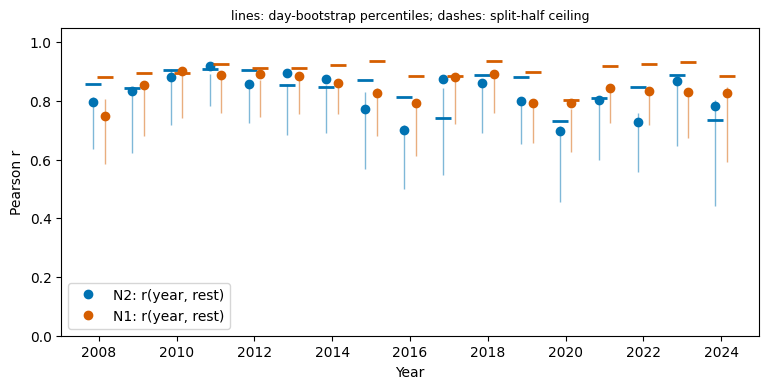

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, c, off in [("N2", "#0072B2", -0.15), ("N1", "#D55E00", 0.15)]:
    z = calib[calib.reference == name]
    ax.vlines(z.year + off, z.pearson_boot_lo, z.pearson_boot_hi, color=c, lw=1, alpha=0.5)
    ax.plot(z.year + off, z.pearson, "o", color=c, label=f"{name}: r(year, rest)")
    ax.plot(z.year + off, z.ceiling, "_", ms=12, color=c, mew=2)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Pearson r")
ax.set_xlabel("Year")
ax.legend(loc="lower left")
ax.set_title("lines: day-bootstrap percentiles; dashes: split-half ceiling", fontsize=9)
display_figure(fig, "calibrated_annual_stability")
